# Analise Exploratíria de Dados (EDA)

**Perguntas de negócio a ser avaliadas:**

1) É possível agrupar as categproas de anfitrião?

2) É possível agrupar as categorias de imóveis alugados?

3) É possível agrupar informações sobre os inquilinos?



---

### Sumário

| Seção | Tópico |
| :--- | :--- |
| [1.0](#1.0) | Configuração do Ambiente |
| [2.0](#2.0) | Análise de Nulos, Valores Únicos e Duplicatas |
| [3.0](#3.0) | Entendendo o Dataset e as Features |
| [4.0](#4.0) | Análise de Features — `price` e demais numéricas |
| [5.0](#5.0) | Feature Engineering — encoding, features derivadas, exportação |

___

## 1.0 Configuracao do Ambiente



In [1]:
import os
import sys
import warnings
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import RobustScaler
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('..'))
%load_ext autoreload
%autoreload 2

from utils_2 import histograma_simples,resumo_estatistico,plot_boxplot_outliers,plot_distribuicao,resumo_estatistico_numerico,analisar_multicolinearidade_pares,plot_matriz_correlacao

warnings.filterwarnings('ignore')


In [2]:
# Configurando o diretório

# OBS = O arquivo é puxado dentro de data/raw

nome_arquivo = 'AB_NYC_2019.csv'

DIR_ATUAL = os.getcwd() 

DIR_ARQ  = os.path.join(DIR_ATUAL,'..','data','raw', nome_arquivo)

DIR_EXP = os.path.join(DIR_ATUAL,'..','data','processed')

df = pd.read_csv(DIR_ARQ)


In [3]:
df.head(20)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
5,5099,Large Cozy 1 BR Apartment In Midtown East,7322,Chris,Manhattan,Murray Hill,40.74767,-73.97500,Entire home/apt,200,3,74,2019-06-22,0.59,1,129
6,5121,BlissArtsSpace!,7356,Garon,Brooklyn,Bedford-Stuyvesant,40.68688,-73.95596,Private room,60,45,49,2017-10-05,0.40,1,0
7,5178,Large Furnished Room Near B'way,8967,Shunichi,Manhattan,Hell's Kitchen,40.76489,-73.98493,Private room,79,2,430,2019-06-24,3.47,1,220
8,5203,Cozy Clean Guest Room - Family Apt,7490,MaryEllen,Manhattan,Upper West Side,40.80178,-73.96723,Private room,79,2,118,2017-07-21,0.99,1,0
9,5238,Cute & Cozy Lower East Side 1 bdrm,7549,Ben,Manhattan,Chinatown,40.71344,-73.99037,Entire home/apt,150,1,160,2019-06-09,1.33,4,188


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

>
> **16 colunas totais**
>
> **48.895 dados**
>
> `6 features categóricas`
>
> `10 features numéricas`

___
 
## 2.0 Análise de Nulos, Valores Únicos e Duplicatas


In [5]:
# quantidade de valores únicos:

dic = {}

for coluna in df.columns:

    unicos = len(df[coluna].unique())

    dic[coluna] = unicos


df_unicos = pd.Series(dic, name='quantidade_unicos').to_frame()

df_unicos.sort_values(by ='quantidade_unicos', ascending = True)


,quantidade_unicos
room_type,3
neighbourhood_group,5
calculated_host_listings_count,47
minimum_nights,109
neighbourhood,221
availability_365,366
number_of_reviews,394
price,674
reviews_per_month,938
last_review,1765


>
> **todos os ID são diferentes**
>
>
> `room_type e neighbourhood_group` possuem **poucos valores únicos**, podem garantir bom poder de agrupamento
>
>
>

In [6]:
df['neighbourhood_group'].value_counts()

neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64

In [7]:
df['room_type'].value_counts()

room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64

>
> Veja que as colunas de `room_type` possuem um **valor quualitativo**
>
> - Claro que Entire_HOme é melhor que Private que é melhor que Shared Room 
> 
> **Podemos atribuir um ordinal encoding interesante**
>

In [8]:
# quantidade de nulos em cada feature

dic = {}

for coluna in df.columns:

    total = df[coluna].shape[0]

    nao_nulos = df[coluna].dropna().shape[0]

    dif = total-nao_nulos

    dic[coluna] = dif

df_nulos = pd.Series(dic, name='quantidade_nulos').to_frame()

df_nulos.sort_values(by = 'quantidade_nulos', ascending = False)



,quantidade_nulos
last_review,10052
reviews_per_month,10052
host_name,21
name,16
neighbourhood_group,0
neighbourhood,0
id,0
host_id,0
longitude,0
latitude,0


>
> As features **last_review e reviews_per_month**  tem muitos valores nulos.
>
> `Reviews_per_month pode sofrer o fill de nulos com o zero`, mas **last_review não, pois o zero indica um valor qualitativo enorme**
>

In [9]:
#quantidade de duplicatas

dic = {}

for coluna in df.columns:

    total = df[coluna].shape[0]

    nao_dup= df[coluna].drop_duplicates().shape[0]

    dif = total-nao_dup

    dic[coluna] = dif

df_nulos = pd.Series(dic, name='quantidade_duplicadas').to_frame()

df_nulos.sort_values(by = 'quantidade_duplicadas', ascending = False)



,quantidade_duplicadas
room_type,48892
neighbourhood_group,48890
calculated_host_listings_count,48848
minimum_nights,48786
neighbourhood,48674
availability_365,48529
number_of_reviews,48501
price,48221
reviews_per_month,47957
last_review,47130


___

## 3.0 Entendendo o Dataset e as Features

Avaliando cada feature para observar possíveis tratamentos ou análises:

| Feature | Análise | Ação / Tratamento |
| :--- | :--- | :--- |
| `host_id` | Identificador único do dono da casa. Alta cardinalidade, não fornece info útil | **Remover** |
| `neighbourhood_group` | Região de NY (Ex: Manhattan, Brooklyn). Apenas 5 valores únicos. Bom para agrupar | **Feature Engineering** (One-Hot Encoding) |
| `neighbourhood` | Bairro específico. Mais de 200 valores únicos. Pode causar explosão na dimensionalidade | **Remover** (já temos lat/long e group) |
| `latitude` e `longitude` | Coordenadas geográficas exatas. Excelentes para criar clusters espaciais ou calcular distância até pontos de interesse | **Feature Engineering** |
| `room_type` | Tipo de espaço (Ex: Entire home/apt, Private room). Apenas 3 categorias | **Feature Engineering** (One-Hot Encoding) |
| `price` | Preço por noite em dólares. Variável contínua chave | **Feature Engineering + Análise** |
| `minimum_nights` | Noites mínimas de estadia. Propensa a outliers (ex: locações longas de 365 dias) | **Análise + Feature Engineering** |
| `number_of_reviews` | Número total de avaliações. Pode possuir um aspecto qualitativo explorável | **Manter / Escalonar** |
| `last_review` | Data da última avaliação. Mais de 10 mil nulos (~20%) | **Feature Engineering** (flag `has_reviews`, depois descartar) |
| `reviews_per_month` | Frequência mensal de avaliações. Mede o "giro" de hóspedes. Nulos indicam locais sem avaliações | **Trabalhar Feature Enginnerings** |
| `calculated_host_listings_count` | Quantidade de imóveis do anfitrião. Separa "Anfitriões Profissionais" de "Anfitriões Casuais" | **Feature Engineering** (categorizar em `anfitriao`) |
| `availability_365` | Dias disponíveis no ano. Indica o modelo de negócio (0 = inativo ou totalmente alugado; 365 = disponibilidade total) | **Manter / Escalonar** |

___

## 4.0 Análise de Features

### 4.1 Analisando `price`

In [10]:
resumo_estatistico(df,coluna = 'price')

,Métrica,Valor
0,Média,152.72
1,Mediana,106.00
2,Desvio Padrão,240.15
3,Mínimo,0.00
4,1º Quartil (Q1 - 25%),69.00
5,3º Quartil (Q3 - 75%),175.00
6,Intervalo Interquartil (IQR),106.00
7,Máximo,"10,000.00"
8,Assimetria (Skewness),19.12
9,Curtose (Kurtosis),585.67


>
> Assimetria positiva de **19.12**, extremamente positiva,  indica presença de consideráveis outliers a **direita da curva**
>
> Veja que o **desvio padrão é alto**, e a **média é consideravelmente diferente da mediana**
> 
> `Alta curtose, indicando pico agudo do KDE.`
>

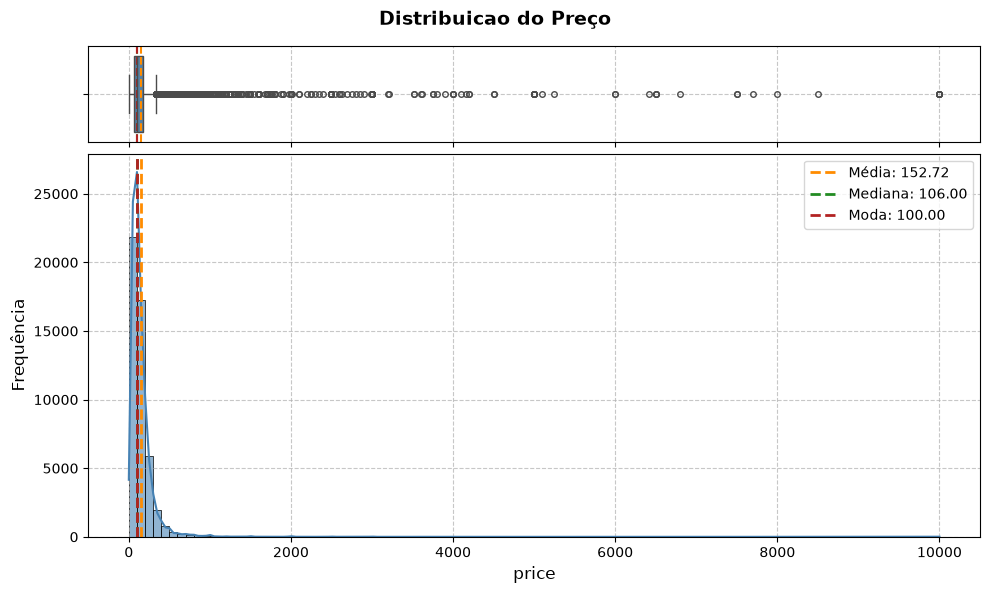

In [11]:
histograma_simples(df,coluna = 'price',bins = 100,titulo = 'Distribuicao do Preço')

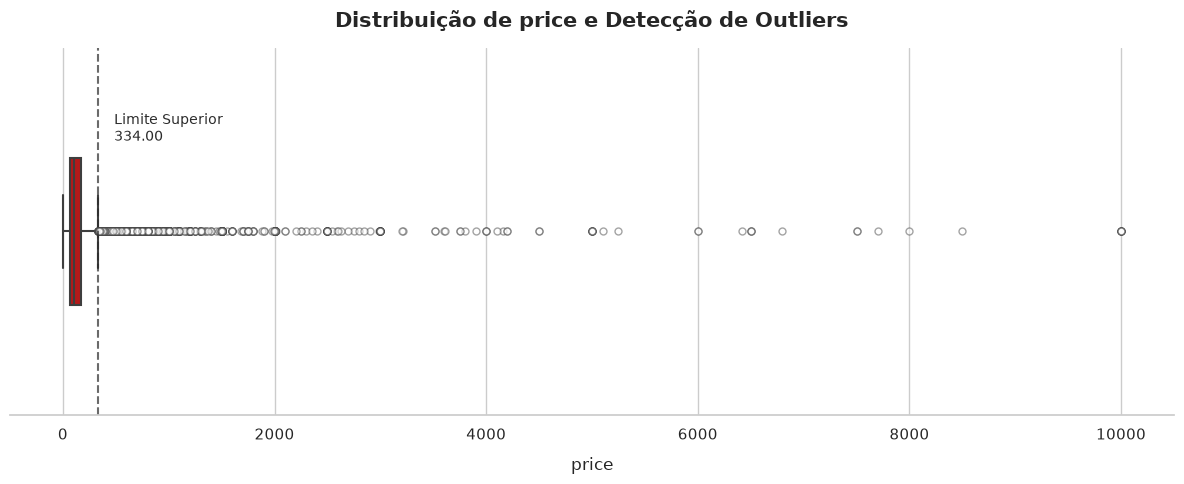

--- Diagnóstico de Outliers: price ---
Limite Superior (Q3 + 1.5*IQR): 334.00
Limite Inferior (Q1 - 1.5*IQR): -90.00
Outliers Superiores: 2972 registros
Outliers Inferiores: 0 registros
Total de Outliers: 2972 (6.08%)


In [12]:
# quantos outliers?
plot_boxplot_outliers(df,coluna = 'price', cor = '#CD0000')

>
> **Muitos outliers, mas todos a direita**
> 

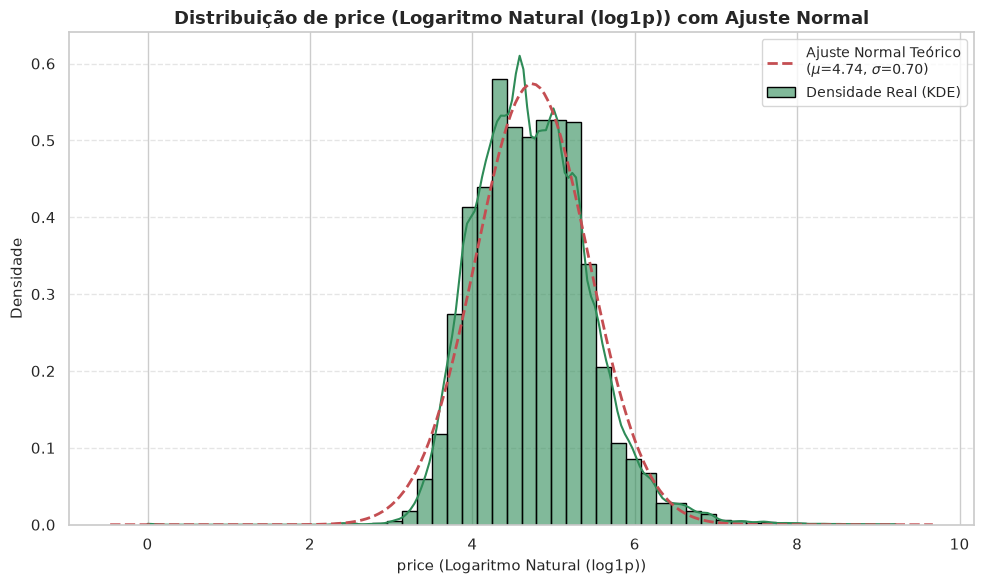

,Transformação,Média,Mediana,Desvio Padrão,Assimetria (Skew),Curtose (Kurt)
0,Logaritmo Natural (log1p),4.7369,4.6728,0.6953,0.5531,1.7427


In [13]:
plot_distribuicao(df,coluna = 'price', transformacao = 'log1p')

>
> **Veja que a transformação logaritmica reduziu absurdamente a assimetria e curtose**
>
> `Será que os outros dados do dataset também possuem essa distribuição tipicamente lognormal?`

>
>

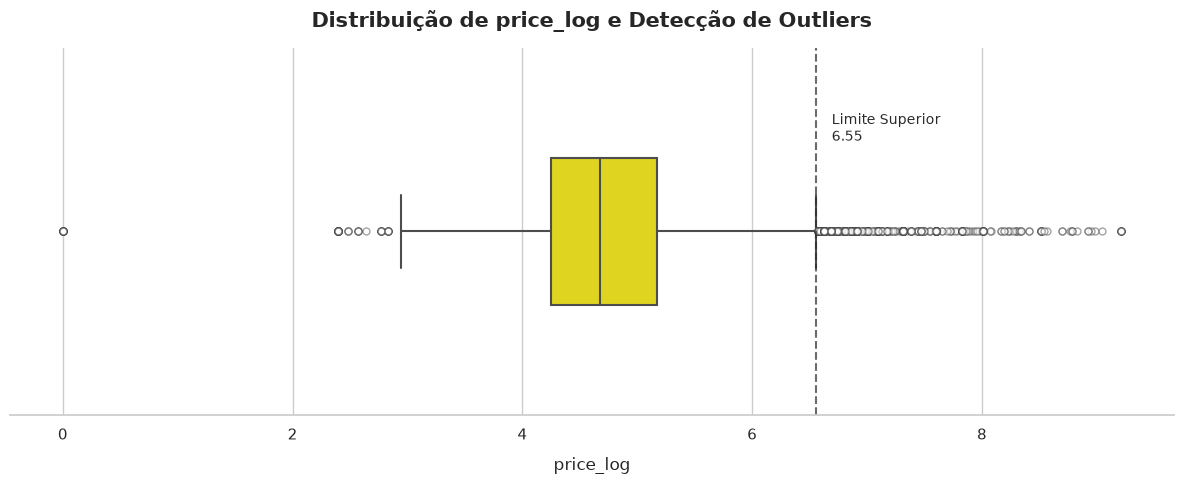

--- Diagnóstico de Outliers: price_log ---
Limite Superior (Q3 + 1.5*IQR): 6.55
Limite Inferior (Q1 - 1.5*IQR): 2.87
Outliers Superiores: 589 registros
Outliers Inferiores: 48 registros
Total de Outliers: 637 (1.30%)


In [14]:
df['price_log'] = np.log1p(df['price']) 

plot_boxplot_outliers(df,coluna = 'price_log',cor = "#FFF000")

>
> **4x menos outliers, IQR controlado**
> 

### 4.2 Análise Conjunta das Demais Features Numéricas

>
> Avaliação de `number_of_reviews`, `reviews_per_month`,
> `calculated_host_listings_count` e `availability_365`.
>
> A assimetria elevada dessas variáveis (assim como `price`) justifica a transformação logarítmica
> para viabilizar o uso em algoritmos baseados em distância euclidiana.
>

In [15]:
colunas = [
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365'
]

df_analise = df[colunas]


resumo_estatistico_numerico(df_analise)

,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
Média,7.03,23.27,1.37,7.14,112.78
Mediana,3.00,5.00,0.72,1.00,45.00
Desvio Padrão,20.51,44.55,1.68,32.95,131.62
Mínimo,1.00,0.00,0.01,1.00,0.00
1º Quartil (Q1 - 25%),1.00,1.00,0.19,1.00,0.00
3º Quartil (Q3 - 75%),5.00,24.00,2.02,2.00,227.00
Intervalo Interquartil (IQR),4.00,23.00,1.83,1.00,227.00
Máximo,"1,250.00",629.00,58.50,327.00,365.00
Assimetria (Skewness),21.83,3.69,3.13,7.93,0.76
Curtose (Kurtosis),854.07,19.53,42.49,67.55,-1.00


>
>
> Veja que exceto **avaliability** a `assimetria de todas as outras features numéricas são bizarramente altas`, presença clara de outliers pela diferença de médias e medianas.
>
> **vamos aplicar o log1p de modo a reduzir a assimetria**
>
> Estratégia de usar a modelagem de `distribuição lognormal`

___

## 5.0 Feature Engineering 

>
> As etapas abaixo representam a análise exploratória das transformações.
> O pipeline completo e definitivo está implementado na **Seção 6.0** via `pipeline_clusterizacao()`.
>

### 5.1 Tratamento de Nulos e Transformação Logarítmica

>
> - Nulos em `reviews_per_month` são preenchidos com 0 (imóveis sem avaliação).
>
> **A transformação `np.log1p` é aplicada para reduzir assimetria e comprimir outliers**


In [16]:
# Trata os nulos de reviews_per_month antes do log 
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# Lista das features que receberam log
features_log = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count'
]

# Cria as novas colunas com sufixo '_log' aplicando log1p
novas_colunas_log = []
for col in features_log:
    col_log = f"{col}_log"
    df[col_log] = np.log1p(df[col])
    novas_colunas_log.append(col_log)

df_analise = df[novas_colunas_log]

resumo_estatistico_numerico(df_analise)

,price_log,minimum_nights_log,number_of_reviews_log,reviews_per_month_log,calculated_host_listings_count_log
Média,4.74,1.50,1.99,0.54,1.09
Mediana,4.67,1.39,1.79,0.31,0.69
Desvio Padrão,0.70,0.87,1.56,0.58,0.86
Mínimo,0.00,0.69,0.00,0.00,0.69
1º Quartil (Q1 - 25%),4.25,0.69,0.69,0.04,0.69
3º Quartil (Q3 - 75%),5.17,1.79,3.22,0.95,1.10
Intervalo Interquartil (IQR),0.92,1.10,2.53,0.91,0.41
Máximo,9.21,7.13,6.45,4.09,5.79
Assimetria (Skewness),0.55,1.50,0.36,0.95,3.28
Curtose (Kurtosis),1.74,1.98,-0.93,-0.11,11.80


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 21 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id                                  48895 non-null  int64  
 1   name                                48879 non-null  str    
 2   host_id                             48895 non-null  int64  
 3   host_name                           48874 non-null  str    
 4   neighbourhood_group                 48895 non-null  str    
 5   neighbourhood                       48895 non-null  str    
 6   latitude                            48895 non-null  float64
 7   longitude                           48895 non-null  float64
 8   room_type                           48895 non-null  str    
 9   price                               48895 non-null  int64  
 10  minimum_nights                      48895 non-null  int64  
 11  number_of_reviews                   48895 non-null  

>
> **Estamos trabalhando com 20 colunas, vamos agora fazer a remoção inicial das features e determinados encondings**
> 
> `Devemos tratar as features categóricas`
>
> `Devemos remover as colunas já transformadas em log1p`

In [18]:
df_tratado = df.copy()

### 5.2 Remoção de Features e Encoding

>
> Aplica Ordinal Encoding em `room_type` (Shared=0, Private=1, Entire=2), One-Hot Encoding em
> `neighbourhood_group` e remove colunas de alta cardinalidade ou substituídas por versões transformadas.
>

In [19]:
# Tratamento de Features e Remoção 

# (1) Ordinal Encoding no Room_type:
mapa = {'Entire home/apt': 2, 'Private room': 1, 'Shared room': 0}
df_tratado['room_type'] = df_tratado['room_type'].map(mapa)

# (2) One-Hot Encoding no NeighBourhood Group (5 uniques gerando 4 colunas)
df_tratado = pd.get_dummies(
    df_tratado, 
    columns=['neighbourhood_group'], 
    drop_first=True, 
    dtype=int
)

# (4) Removendo features desnecessárias ou já transformadas:
colunas_remover = [
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'host_id',
    'neighbourhood',
    'last_review',
    'id',
    'price',
    'host_name',
    'name',
]

df_tratado = df_tratado.drop(columns = colunas_remover)

# Diagnóstico final
df_tratado.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 13 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   latitude                            48895 non-null  float64
 1   longitude                           48895 non-null  float64
 2   room_type                           48895 non-null  int64  
 3   availability_365                    48895 non-null  int64  
 4   price_log                           48895 non-null  float64
 5   minimum_nights_log                  48895 non-null  float64
 6   number_of_reviews_log               48895 non-null  float64
 7   reviews_per_month_log               48895 non-null  float64
 8   calculated_host_listings_count_log  48895 non-null  float64
 9   neighbourhood_group_Brooklyn        48895 non-null  int64  
 10  neighbourhood_group_Manhattan       48895 non-null  int64  
 11  neighbourhood_group_Queens          48895 non-null  

### 5.3 Criação de Features Derivadas

>
> **Features criadas a partir das features  originais para capturar efeitos de sinergia**
>
> - Features Criadas:
>
> `distancia_Times_Square` --> **distância euclidiana até o ponto da times square ( principal pto turístico)** --> Capturar informações sobre o lugar
>
> `Custo_estadia` --> **Diária * Numero mínimo de noites** + Transformação log1p --> Capturar informações sobre o usuário
>
> `Volume_oferta_dias` --> **Avaliabilidade do imóveis * quantidade de imóveis do host** --> Capturar informações sobre o anfitrião
>
> `Taxa_Reviews_mes` --> **Numero de reviews totais / NUmero de reviews por mês** --> Capturar informações sobre o lugar

In [20]:
# Criação de Features Derivadas

# (1) Distância até a Times Square (centro turístico principal)
ts_lat, ts_lon = 40.7580, -73.9855
df_tratado['distancia_Times_Square'] = np.sqrt(
    (df_tratado['latitude'] - ts_lat)**2 +
    (df_tratado['longitude'] - ts_lon)**2
)

# (2) Custo total da estadia mínima com transformação logarítmica
df_tratado['custo_estadia_log'] = np.log1p(df['price'] * df['minimum_nights'])

# (3) Volume de oferta do anfitrião (dias disponíveis × total de imóveis)
df_tratado['volume_oferta_dias_anfitriao_log'] = (
    df['availability_365'] * df['calculated_host_listings_count']
)

# (4) Taxa de reviews por mês (eficiência de conversão de hóspedes em avaliadores)
df_tratado['taxa_reviews_mes'] = df['number_of_reviews'] / (df['reviews_per_month'] + 1e-6)

In [21]:
df_remover_geografico = [
    'latitude',
    'longitude'
]

df_tratado = df_tratado.drop(columns = df_remover_geografico)

>
> A feature de distância substitue a necessidade de uso da **latitude e longitude pura**
>

In [22]:
df_tratado.head(20)

,room_type,availability_365,price_log,minimum_nights_log,number_of_reviews_log,reviews_per_month_log,calculated_host_listings_count_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square,custo_estadia_log,volume_oferta_dias_anfitriao_log,taxa_reviews_mes
0,1,365,5.010635,0.693147,2.302585,0.190620,1.945910,1,0,0,0,0.111287,5.010635,2190,42.856939
1,2,355,5.420535,0.693147,3.828641,0.322083,1.098612,0,1,0,0,0.004709,5.420535,710,118.420741
2,1,365,5.017280,1.386294,0.000000,0.000000,0.693147,0,1,0,0,0.067112,6.111467,365,0.000000
3,2,194,4.499810,0.693147,5.602119,1.729884,0.693147,1,0,0,0,0.077273,4.499810,194,58.189643
4,2,0,4.394449,2.397895,2.302585,0.095310,0.693147,0,1,0,0,0.058001,6.685861,0,89.999100
5,2,129,5.303305,1.386294,4.317488,0.463734,0.693147,0,1,0,0,0.014730,6.398595,129,125.423516
6,1,0,4.110874,3.828641,3.912023,0.336472,0.693147,1,0,0,0,0.077011,7.901377,0,122.499694
7,1,220,4.382027,1.098612,6.066108,1.497388,0.693147,0,1,0,0,0.006914,5.068904,220,123.919273
8,1,0,4.382027,1.098612,4.779123,0.688135,0.693147,0,1,0,0,0.047439,5.068904,0,119.191799
9,2,188,5.017280,0.693147,5.081404,0.845868,1.609438,0,1,0,0,0.044825,5.017280,752,120.300661


>
> É fundamental em **clusterização** realizar a `padronização das features` de modo a não **enviesar as normas euclidianas**
>
> os algoritmos usam noções de **distância euclidiana**

In [23]:
df_tratado.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 15 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   room_type                           48895 non-null  int64  
 1   availability_365                    48895 non-null  int64  
 2   price_log                           48895 non-null  float64
 3   minimum_nights_log                  48895 non-null  float64
 4   number_of_reviews_log               48895 non-null  float64
 5   reviews_per_month_log               48895 non-null  float64
 6   calculated_host_listings_count_log  48895 non-null  float64
 7   neighbourhood_group_Brooklyn        48895 non-null  int64  
 8   neighbourhood_group_Manhattan       48895 non-null  int64  
 9   neighbourhood_group_Queens          48895 non-null  int64  
 10  neighbourhood_group_Staten Island   48895 non-null  int64  
 11  distancia_Times_Square              48895 non-null  

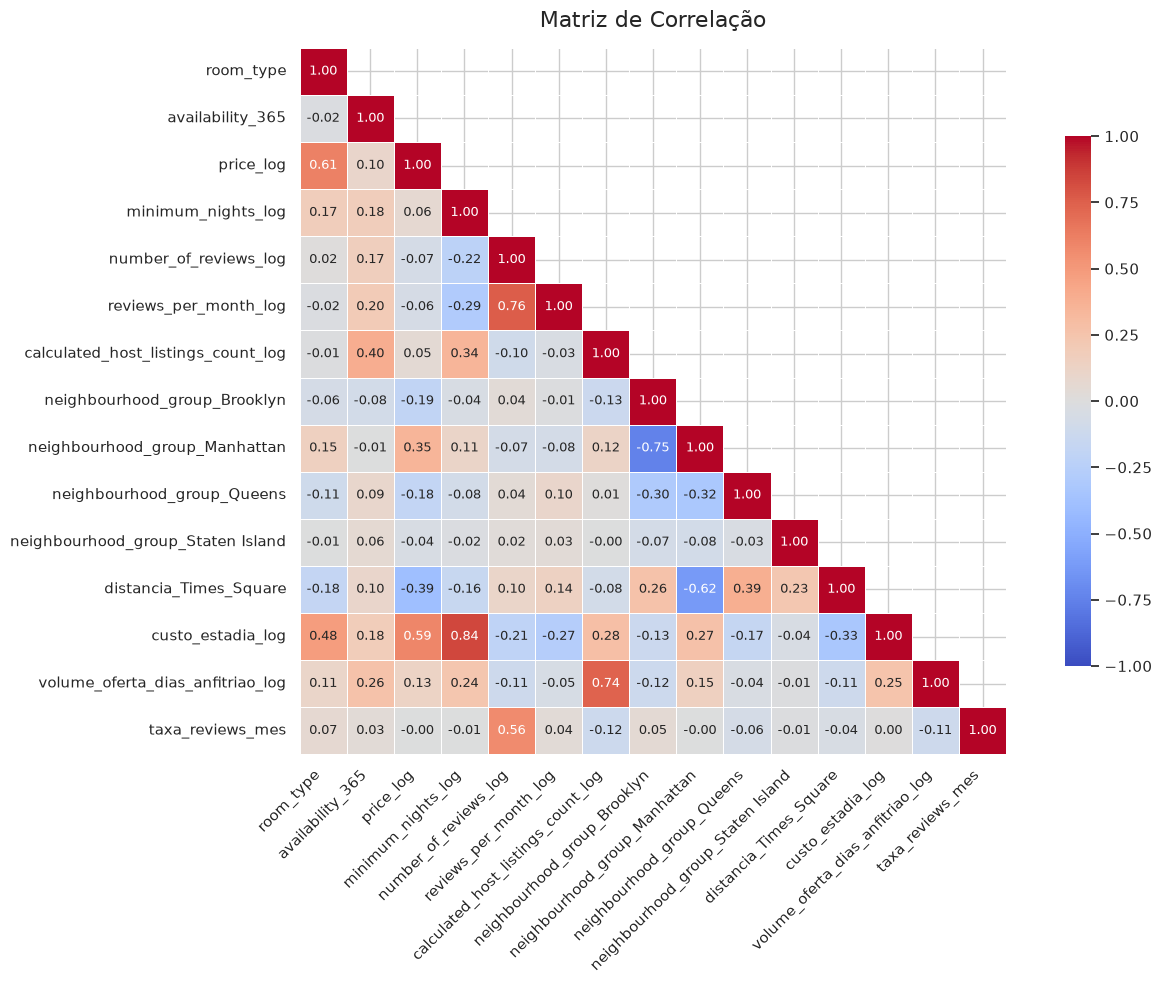

,room_type,availability_365,price_log,minimum_nights_log,number_of_reviews_log,reviews_per_month_log,calculated_host_listings_count_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square,custo_estadia_log,volume_oferta_dias_anfitriao_log,taxa_reviews_mes
room_type,1.000000,-0.022500,0.610417,0.173521,0.015128,-0.020315,-0.010567,-0.062830,0.149209,-0.106850,-0.007752,-0.179102,0.476790,0.106508,0.068145
availability_365,-0.022500,1.000000,0.098558,0.178339,0.171066,0.197450,0.398314,-0.079671,-0.005434,0.087113,0.057885,0.101384,0.181831,0.263582,0.033662
price_log,0.610417,0.098558,1.000000,0.063577,-0.066145,-0.060988,0.049395,-0.192346,0.347058,-0.182790,-0.044101,-0.391223,0.589152,0.131985,-0.004278
minimum_nights_log,0.173521,0.178339,0.063577,1.000000,-0.221071,-0.294625,0.344036,-0.041618,0.110955,-0.080694,-0.022556,-0.155460,0.839251,0.235014,-0.007286
number_of_reviews_log,0.015128,0.171066,-0.066145,-0.221071,1.000000,0.760737,-0.095789,0.035493,-0.072327,0.041432,0.024748,0.102892,-0.207071,-0.114980,0.564867
reviews_per_month_log,-0.020315,0.197450,-0.060988,-0.294625,0.760737,1.000000,-0.033615,-0.008060,-0.075124,0.099296,0.034110,0.143664,-0.272132,-0.051882,0.035395
calculated_host_listings_count_log,-0.010567,0.398314,0.049395,0.344036,-0.095789,-0.033615,1.000000,-0.130904,0.124105,0.013710,-0.001527,-0.082805,0.284878,0.742150,-0.120999
neighbourhood_group_Brooklyn,-0.062830,-0.079671,-0.192346,-0.041618,0.035493,-0.008060,-0.130904,1.000000,-0.745240,-0.302527,-0.073265,0.263138,-0.127686,-0.118687,0.054479
neighbourhood_group_Manhattan,0.149209,-0.005434,0.347058,0.110955,-0.072327,-0.075124,0.124105,-0.745240,1.000000,-0.322875,-0.078193,-0.617991,0.269891,0.150310,-0.001736
neighbourhood_group_Queens,-0.106850,0.087113,-0.182790,-0.080694,0.041432,0.099296,0.013710,-0.302527,-0.322875,1.000000,-0.031742,0.389360,-0.168058,-0.038090,-0.062747


In [24]:
plot_matriz_correlacao(df_tratado,titulo = 'Matriz de Correlação', triangulo = True)

In [25]:
analisar_multicolinearidade_pares(df_tratado,limite = 0.7)

--- Pares com Correlação > 0.7 ---
minimum_nights_log & custo_estadia_log: 0.839
number_of_reviews_log & reviews_per_month_log: 0.761
neighbourhood_group_Brooklyn & neighbourhood_group_Manhattan: 0.745
calculated_host_listings_count_log & volume_oferta_dias_anfitriao_log: 0.742


>
> Nao tem como analisar IV para escolher a feature a se manter pois **não há target**
>
> Na dúvida, as features escolhidas serão as **criadas** pois carregam mais valor preditivo
>
> Features geográficas (do one-hot) **não serão removidas**, carregam valor preditivo a despeito da correlação alta.
>

In [26]:
# Privilegiando FEATURES CRIADAS em vez de originais, tendem a agregar mais valor preditivo:


# - custo_estadia_log mantida  (derivada de minimum_nights × price)

# - volume_oferta_dias_anfitriao_log mantida  (derivada de availability_365 × calculated_host_listings_count)

# - reviews_per_month_log mantida  (mais informativa que number_of_reviews_log para medir giro)


colunas_remov_corr = [
    'minimum_nights_log',                    # removida em favor de custo_estadia_log
    'calculated_host_listings_count_log',    # removida em favor de volume_oferta_dias_anfitriao_log
    'number_of_reviews_log',                 # removida em favor de reviews_per_month_log
]

# As geográficas não serão removidos pois elas carregam um valor intrínseco 

df_tratado = df_tratado.drop(columns=colunas_remov_corr)

In [27]:
df_tratado.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   room_type                          48895 non-null  int64  
 1   availability_365                   48895 non-null  int64  
 2   price_log                          48895 non-null  float64
 3   reviews_per_month_log              48895 non-null  float64
 4   neighbourhood_group_Brooklyn       48895 non-null  int64  
 5   neighbourhood_group_Manhattan      48895 non-null  int64  
 6   neighbourhood_group_Queens         48895 non-null  int64  
 7   neighbourhood_group_Staten Island  48895 non-null  int64  
 8   distancia_Times_Square             48895 non-null  float64
 9   custo_estadia_log                  48895 non-null  float64
 10  volume_oferta_dias_anfitriao_log   48895 non-null  int64  
 11  taxa_reviews_mes                   48895 non-null  float64
dtypes

>
> Fechamos a análise em **12 colunas otimizadas**
>
> Todas as colunas já foram padronizadas e tratadas os nulos
>

### 5.4 Exportação do Dataset Processado

>
> O dataset escalonado (`df_tratado`) é exportado para `data/processed/master.csv`.


In [28]:
# Exportação do dataset escalonado para a modelagem

nome_processado = 'master.csv'

df_tratado.to_csv(os.path.join(DIR_EXP, nome_processado), index=False)

print(f'Dataset exportado com {df_tratado.shape[0]:,} linhas x {df_tratado.shape[1]} colunas')

Dataset exportado com 48,895 linhas x 12 colunas
